# Notebook to setup the radcalnet_oc package

In [1]:

import os, shutil
import glob

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]

plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
import numpy as np
import xarray as xr
import pandas as pd

import radcalnet_oc as radoc
#from radcalnet_oc import acutils
print(f'-radcalnet_oc: {radoc.__version__}')


-radcalnet_oc: 0.0.2


## Load look-up tables

In [25]:
lut= radoc.LUT()
lut.load_auxiliary_data()
lut.gas_lut
lut.aero_lut

INFO:root:loading look-up tables
INFO:root:loading look-up tables


<xarray.Dataset> Size: 3GB
Dimensions:            (wind: 6, model: 6, aot_ref: 10, wl: 10, sza: 45,
                        vza: 34, azi: 73)
Coordinates:
  * wl                 (wl) float32 40B 350.0 400.0 500.0 ... 2.2e+03 2.5e+03
  * aot_ref            (aot_ref) float32 40B 0.0 0.001 0.01 0.1 ... 0.7 1.0 1.5
  * sza                (sza) float32 180B 0.0 2.0 4.0 6.0 ... 84.0 86.0 88.0
  * wind               (wind) float64 48B 0.5 2.0 4.0 8.0 12.0 16.0
  * vza                (vza) float32 136B 0.0 1.14 2.62 ... 45.93 47.43 48.92
  * azi                (azi) float32 292B 0.0 5.0 10.0 ... 350.0 355.0 360.0
  * model              (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
Data variables: (12/13)
    wl_ref             (wind, model, aot_ref, wl) float32 14kB ...
    Cext_ref           (wind, model, aot_ref, wl) float32 14kB ...
    ssa_ref            (wind, model, aot_ref, wl) float32 14kB ...
    aot                (model, aot_ref, wl) float32 2kB ...
    Cext               (wind, model, aot_ref, wl) float32 14kB ...
    ssa                (wind, model, aot_ref, wl) float32 14kB ...
    ...                 ...
    bbp_ratio          (wind, model, aot_ref, wl) float32 14kB ...
    bup_ratio          (wind, model, aot_ref, wl) float32 14kB ...
    vol_mean_particle  (wind, model, aot_ref, wl) float32 14kB ...
    nr                 (wind, model, aot_ref, wl) float32 14kB ...
    Ed                 (wind, model, aot_ref, wl, sza) float32 648kB ...
    I                  (wind, model, aot_ref, wl, sza, vza, azi) float64 3GB ...

## Set total column integrated concentration of absorbing gases and zenith angles (sza:sun and vza:viewing)

In [3]:
48*2.69/6.02


21.448504983388705

In [4]:

sza=40
vza=0
pressure=1000

#water vapor in cm
tpw_cm=6

#ozone in dobson
to3_du=350 

#NO2 (micromol.m-2)
tcno2_micmol_m2=100

# ch4 in kg.m-2
tcch4= 1e-2

# unit conversion
# tcwv cm into kg.m-2
tcwv=tpw_cm*10 

# conversion O3 du to kg.m-2
tco3=to3_du *2.14485e-5

# conversion NO2 micromol.m-2 into kg.m-2
tcno2=tcno2_micmol_m2*46.0e-9
tcno2

4.6e-06

In [5]:
6.4286e-3/300

2.1428666666666667e-05

## Compute spectral transmittances

In [23]:
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.air_mass=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.gas_tc['no2'] = tcno2

##################################################
params = r'$sza= %.1f \ deg.$ ' % (sza) + \
        '\n$vza= %.1f\ deg.$' % (vza) + \
        '\n$pressure = %.1f\ hPa$' % (pressure) + \
        '\n$tcwv = %.1f\ kg\cdot m^{-2}$' % (tcwv) + \
        '\n$tco3 = %.1e\ kg\cdot m^{-2}$' % (tco3) 

# set total transmittance values
gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

In [7]:
#water vapor in cm
tpw_cm=.6

#ozone in dobson
to3_du=270 

#NO2 (micromol.m-2)
tcno2_micmol_m2=100

# ch4 in kg.m-2
tcch4= 1e-2

# unit conversion
# tcwv cm into kg.m-2
tcwv=tpw_cm*10 

# conversion O3 du to kg.m-2
tco3=to3_du *2.14485e-5
# set total transmittance values
gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.air_mass=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.gas_tc['no2'] = tcno2

Ttot2=gas_trans.get_gaseous_transmittance()

## Plot results

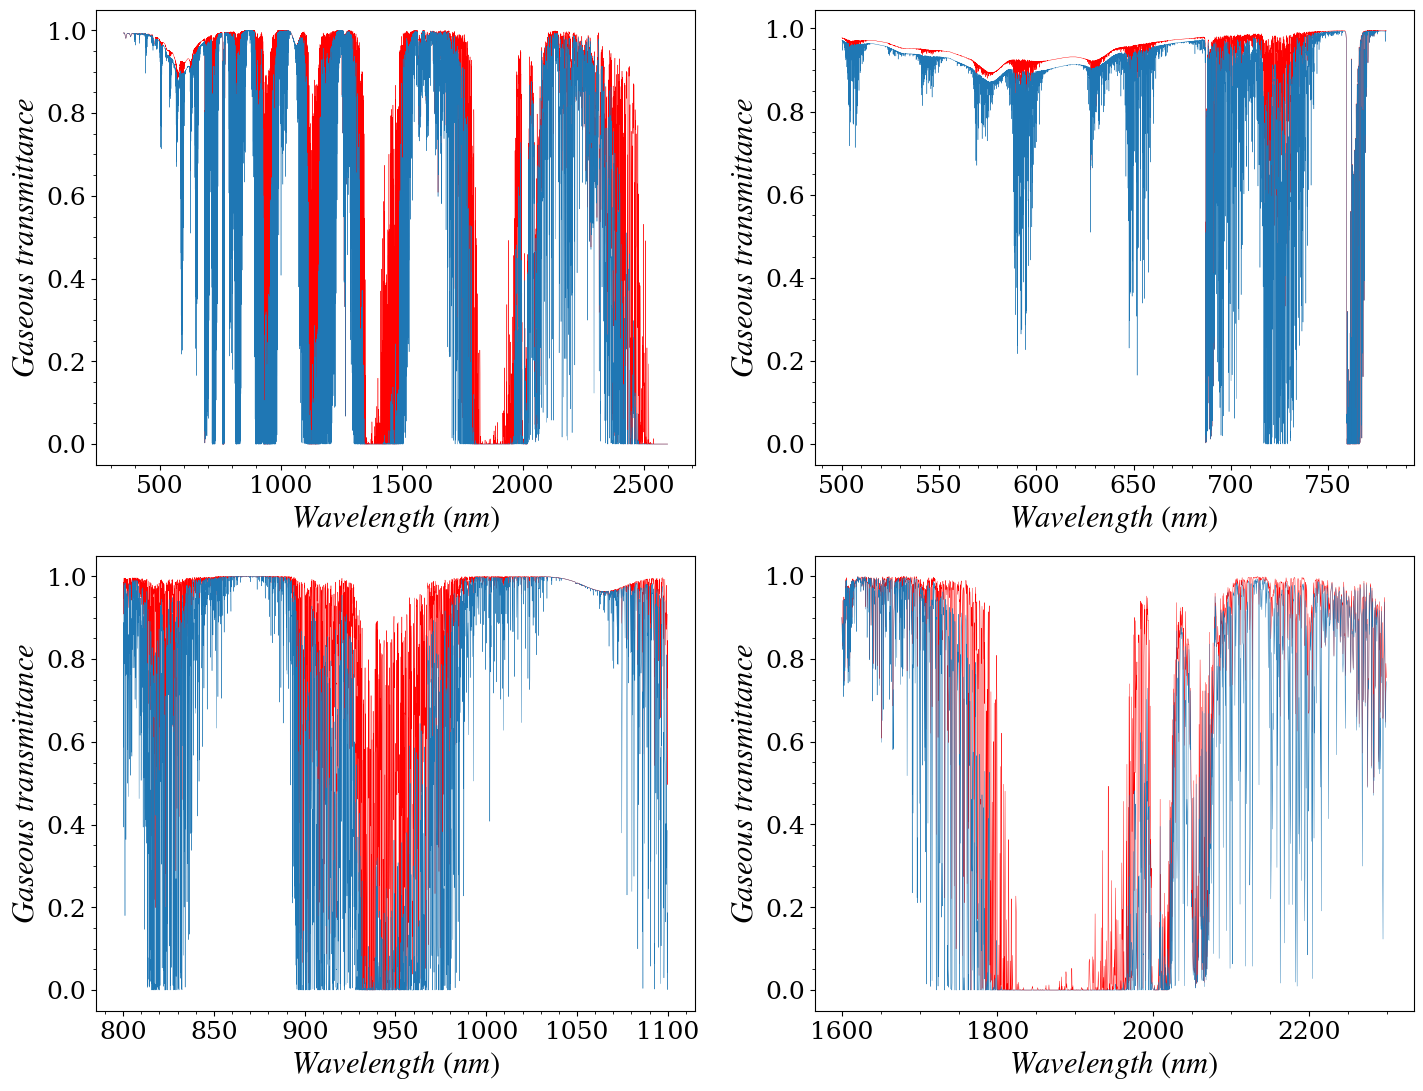

In [8]:


fig,axs = plt.subplots(2,2,figsize=(17,13))
axs=axs.ravel()


Ttot2.plot(lw=0.3,ax=axs[0],c='r')
Ttot.plot(lw=0.3,ax=axs[0])
wl_range=slice(500,780)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],label='Tg')
wl_range=slice(800,1100)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],label='Tg')
wl_range=slice(1600,2300)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],label='Tg')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
    #ax.semilogy()

#plt.semilogy()

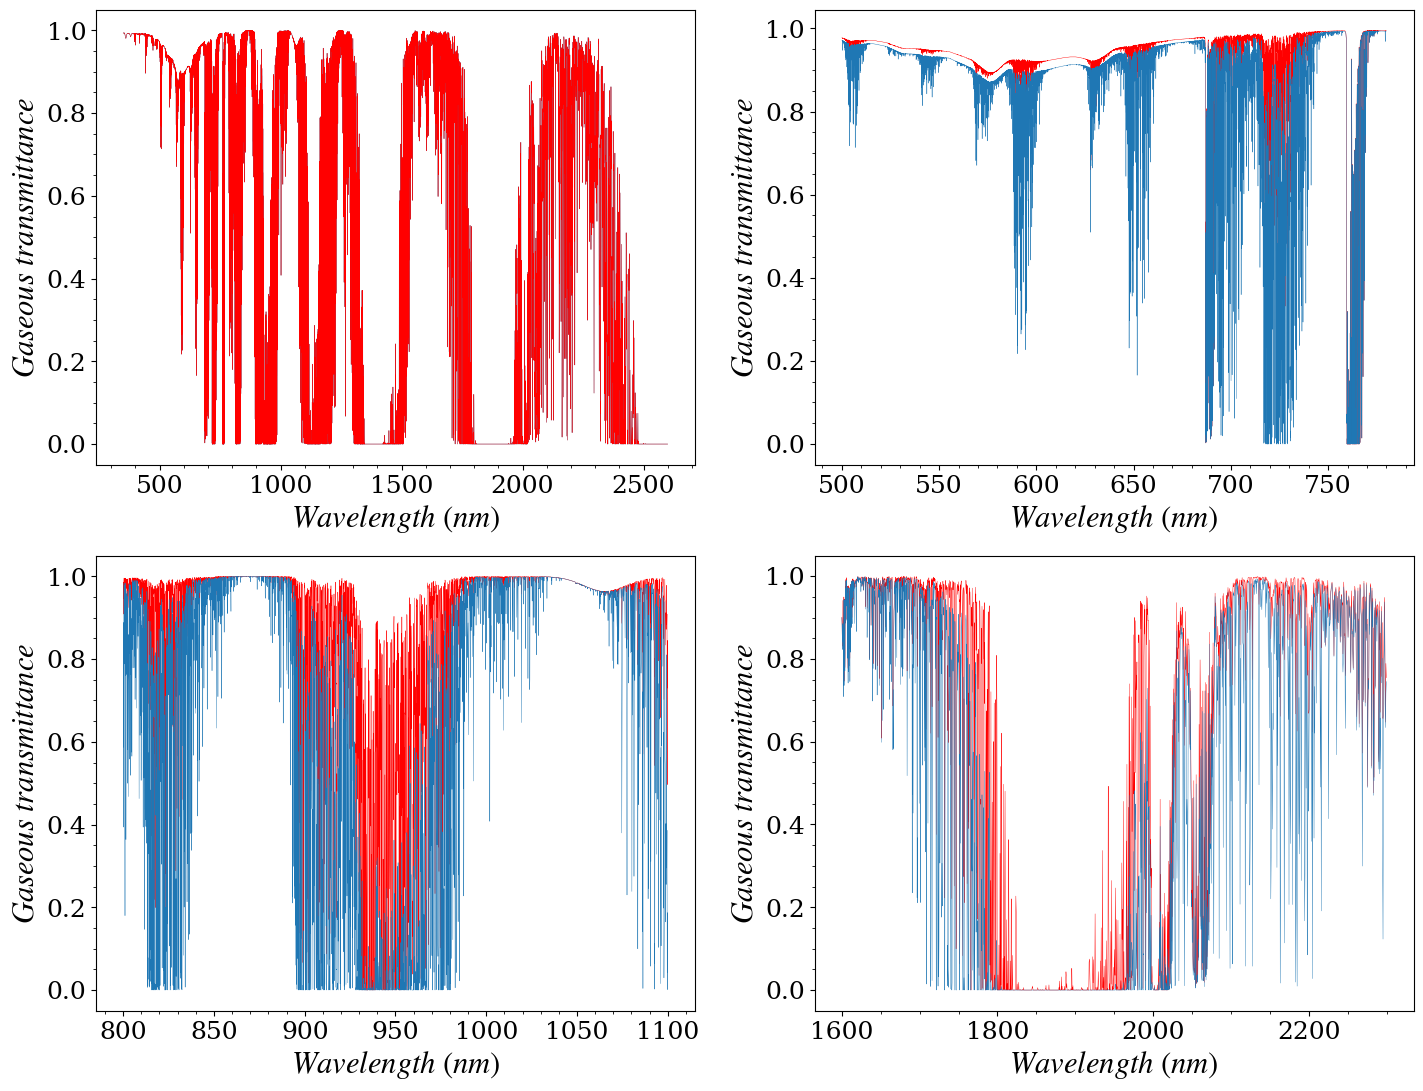

In [9]:


fig,axs = plt.subplots(2,2,figsize=(17,13))
axs=axs.ravel()

Ttot.plot(lw=0.3,ax=axs[0])
Ttot.plot(lw=0.3,ax=axs[0],c='r')

wl_range=slice(500,780)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],label='Tg')
wl_range=slice(800,1100)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],label='Tg')
wl_range=slice(1600,2300)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],label='Tg')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
    #ax.semilogy()

#plt.semilogy()

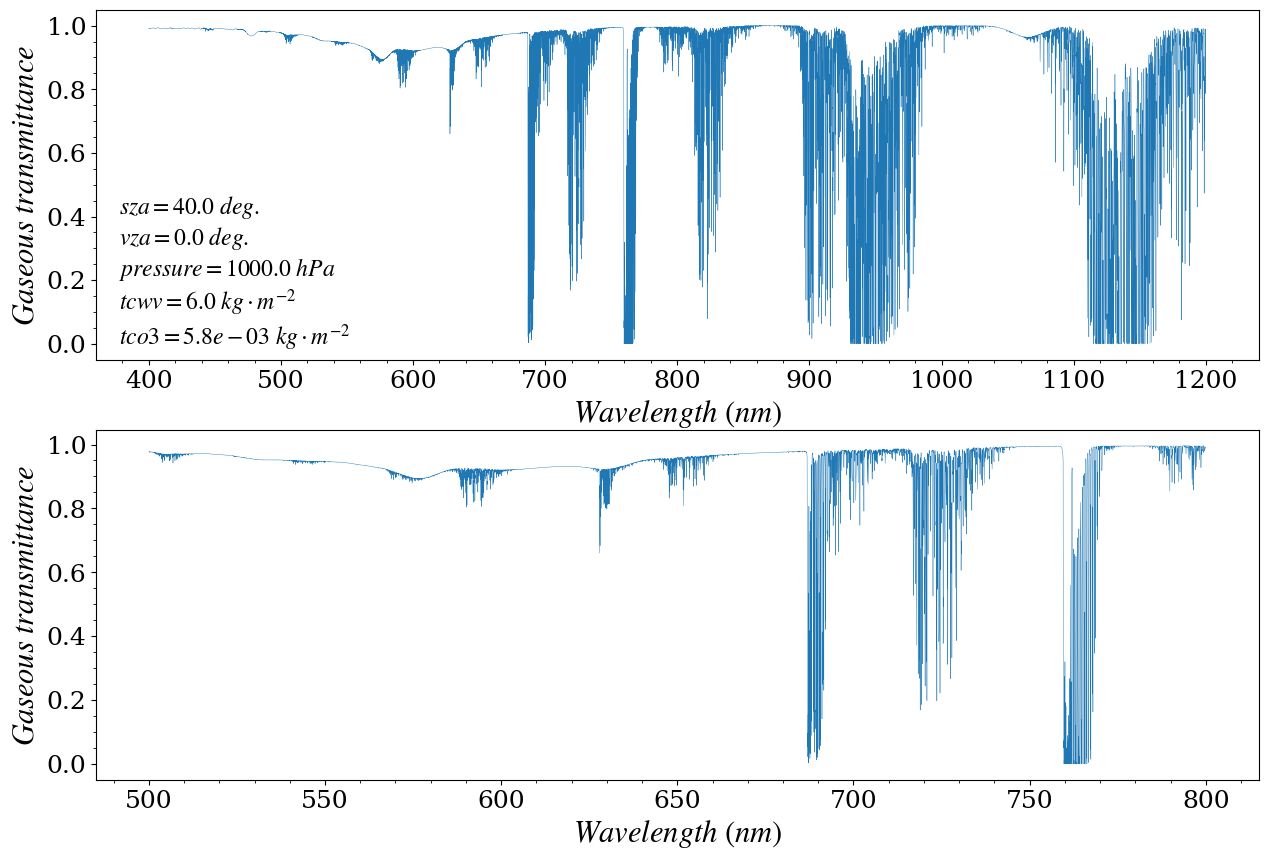

In [24]:


fig,axs = plt.subplots(2,1,figsize=(15,10))
axs=axs.ravel()



wl_range=slice(400,1200)

Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[0],label='Tg')
wl_range=slice(500,800)

Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],label='Tg')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
    #ax.semilogy()
axs[0].text(0.02, 0.02, params, fontsize=17, verticalalignment='bottom', horizontalalignment='left',
                transform=axs[0].transAxes)
#plt.semilogy()
plt.savefig('/DATA/projet/magellium/esa/phy2flex/fig/AC/abs_transmittance_hyperspectral.png',dpi=300, bbox_inches = 'tight')

## Check impact of the spectral resolution (sensor-like)

Spectral resolution is defined by the number (central wavelength: central_wl) and width (gaussian distribution) of spectral bands recorded. The gaussian distribution are computed from the full width at half maximum fwhm given in nanometers.

/tmp/ipykernel_2132721/2061914350.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


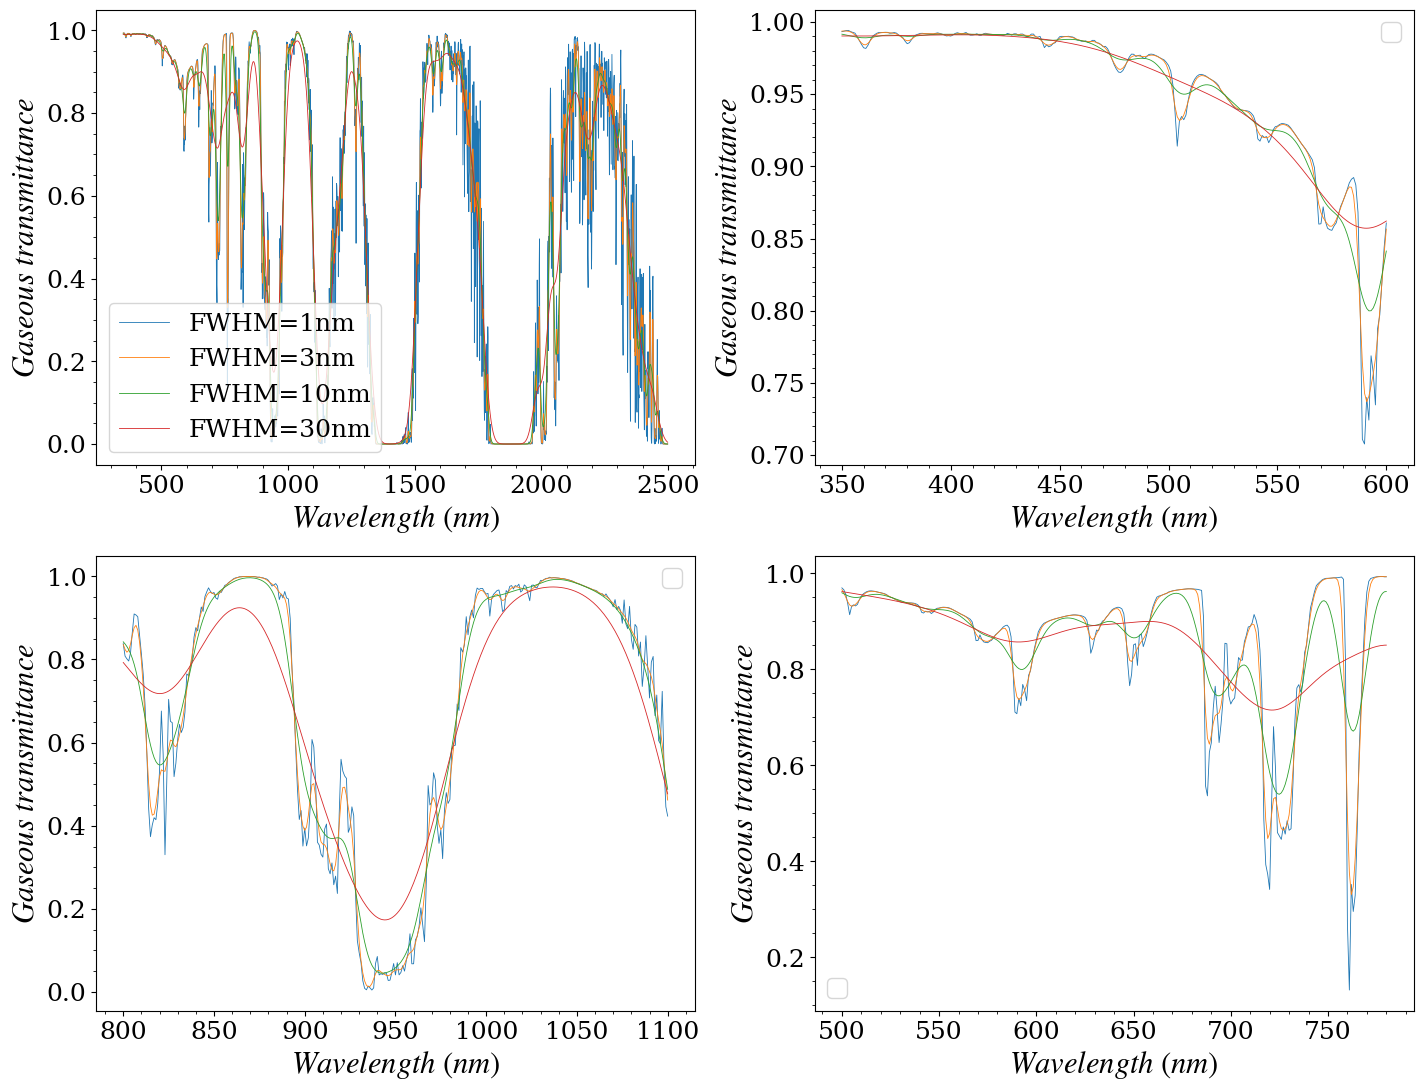

In [10]:

spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)

signal = Ttot
wl_signal = signal.wl.values

fig,axs = plt.subplots(2,2,figsize=(17,13))
axs=axs.ravel()

for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    Tg = spectral.convolve(signal)
    Tg.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    
    wl_range=slice(350,600)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[1])
    
    wl_range=slice(800,1100)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[2])
    wl_range=slice(500,780)
    Tg.sel(wl=wl_range).plot(lw=0.6,ax=axs[3])
    
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()  
    ax.legend()

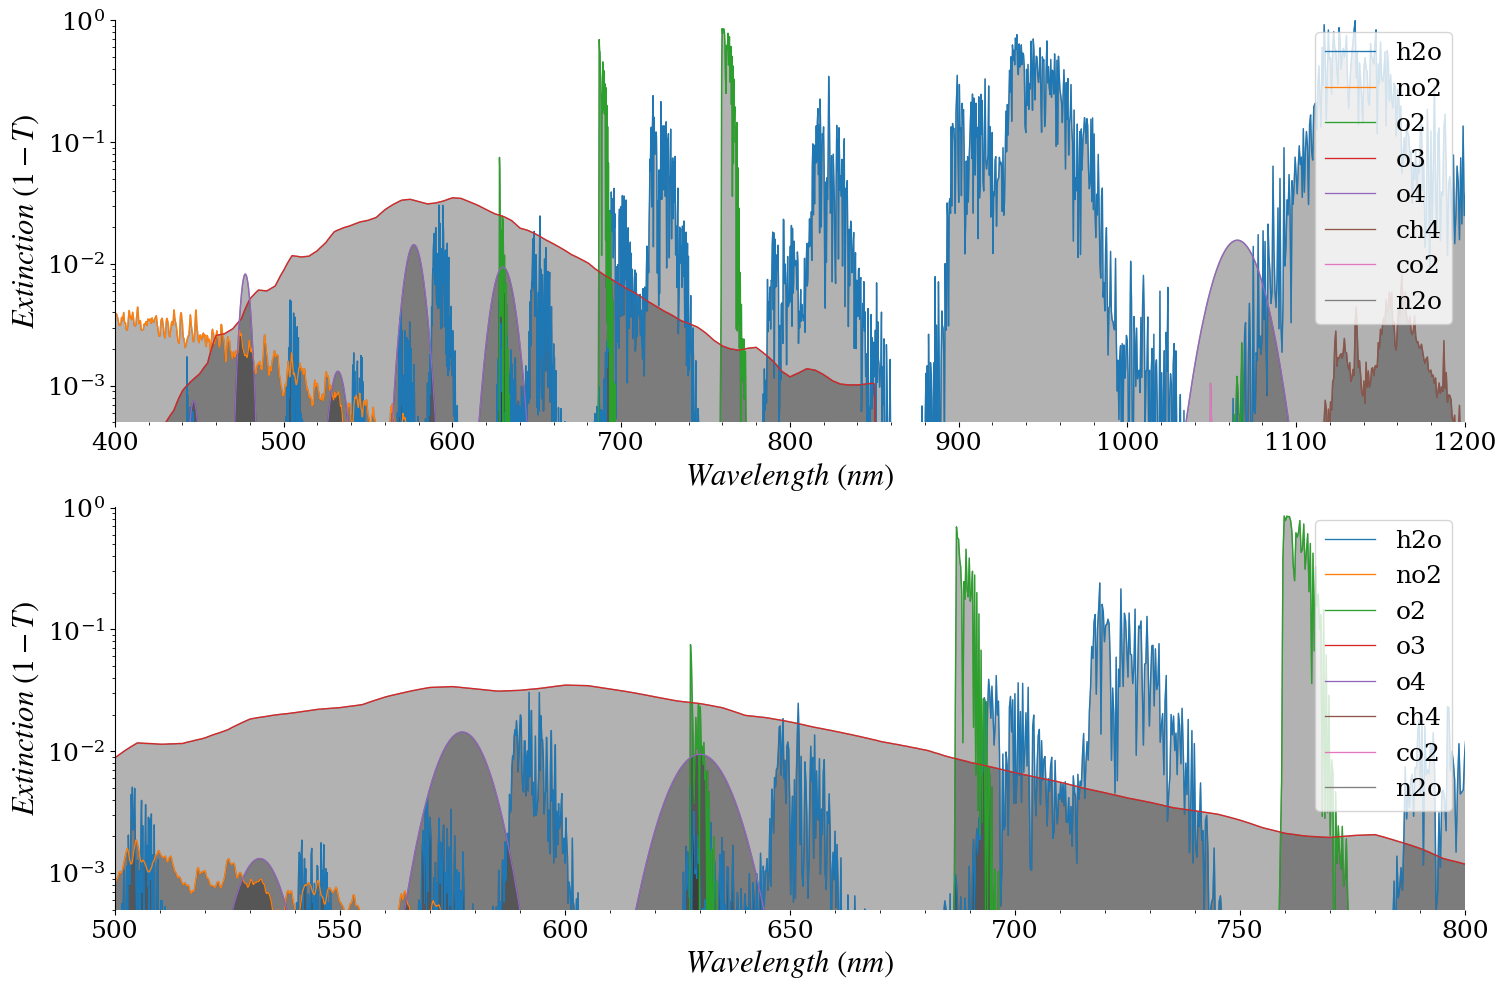

In [14]:
M=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
variable='o4'
variables=['h2o','no2','o2','o3','o4','ch4','co2','n2o']
conc={'ch4':tcch4,'co':1,'co2':1,
      'h2o':tcwv,'n2o':1,'no2':tcno2,
      'o2':1,'o3':tco3,'o4':1}



fig, axs = plt.subplots(nrows=2, sharey=True, figsize=(15, 10))
fig.subplots_adjust(bottom=0.05, top=0.94, left=0.05, right=0.95, hspace=0.21, wspace=0.025)
for iax in range(2):
    for i, variable in enumerate(variables):
        abs_ot = gas_trans.gas_lut[variable]*conc[variable]
        Tg = np.exp(-abs_ot).coarsen(wl=5,boundary='pad').mean()
        axs[iax].minorticks_on()
        axs[iax].spines[['right', 'bottom', 'top']].set_visible(False)
        axs[iax].fill_between(Tg.wl,
                              1 - Tg, color='k', alpha=0.3)
        axs[iax].plot(Tg.wl,
                      1 - Tg,  lw=0.95,label=variable)
   
    axs[iax].set_xlabel(r'$Wavelength\ (nm)$')
    axs[iax].legend()



for i in range(2):
    axs[i].set_ylabel(r'$Extinction\ (1-T)$')

axs[0].set_xlim([400, 1200])
axs[1].set_xlim([500, 800])
axs[0].set_ylim([0.0005, 1.01])
axs[0].semilogy()
plt.savefig('/DATA/projet/magellium/esa/phy2flex/fig/AC/abs_transmittance.png',dpi=300, bbox_inches = 'tight')